# Main Plotting of liftetime exposure for water scarcity -- remake
For water scarcity
Main script for plotting, does analysis based on script

In [1]:
import os
import xarray as xr
import pickle as pk
import time
import matplotlib as mpl
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
import pandas as pd

from settings import *
from load_manip import *
from exposure import * 
from utils import *
from main_function import *
from plotting import *

import warnings
warnings.filterwarnings("ignore")

# set own plotting parameters
set_plot_param()
map_proj = ccrs.Robinson(central_longitude=0, globe=None)


# customized plotting parameters

labelfontsize=12
titlesize=14
labelsize=titlesize
mpl.rc('xtick',labelsize=labelfontsize)
mpl.rc('ytick',labelsize=labelfontsize)
mpl.rc('axes',titlesize=titlesize)
mpl.rc('axes',labelsize=labelsize)
mpl.rc('legend',fontsize='large')

%matplotlib inline 

In [2]:
# extreme event
global flags

flags = {}

flags['mode'] = 'exposure'   # whether to calculate exposure, duration, intensity or all. 

flags['mask'] = 0           # 0: do not process country data (i.e. load masks pickle)
                            # 1: process country data (i.e. produce and save masks as pickle)
flags['exposure_pic'] = 0   # 0: do not process ISIMIP runs to compute picontrol exposure (i.e. load exposure pickle)
                            # 1: process ISIMIP runs to compute picontrol exposure (i.e. produce and save exposure as pickle)
flags['expectancy'] = 0     # 0: Load varying life expectancies
                            # 1: Constant life expectancies at 1960 levels

rcps = ['RCP60','RCP26']
rcp_text = {'RCP60': 'RCP 6.0', 'RCP26' : 'RCP 2.6'  }

labels = ['a.','b.','c.','d.','e.','f.','g.','h.','f.']
labels = ['A','B','C','D','E','F','G','H','F']

regions =['East Asia & Pacific', 'Europe & Central Asia', 'Latin America & Caribbean', 'Middle East & North Africa', 'North America', 'South Asia', 'Sub-Saharan Africa']
# TODO: add rest of flags

### Load and manipulate  files for plotting

In [3]:
# load country borders (from pickles)

d_countries = pd.read_pickle(open('./data/pickles/country_info.pkl', 'rb'))
df_countries = d_countries['info_pop']

# unpack country information
gdf_country_borders = d_countries['borders']

# load cohort info
d_regions = pd.read_pickle(open('./data/pickles/region_info.pkl', 'rb'))

# unpack region information
df_birthyears_regions = d_regions['birth_years']
df_life_expectancy_5_regions = d_regions['life_expectancy_5']
d_cohort_weights_regions = d_regions['cohort_size']
d_cohort_size = d_countries['cohort_size']
d_all_cohorts = d_countries['all_cohorts']

## Calculate water deficit

In [4]:
# Main function to calculate water deficit (%) based on RCP scenarios
def calc_lifetime_waterdeficit_EFRmethod(flags, method="VMF"): 
    
    if method == "VMF":
        flags['extr'] = f'waterdeficit'
    else: 
        flags['extr'] = f'waterdeficit{method}'
    
    
    # load lifetime waterdeficit
    ds_waterdeficit, ds_waterdeficit_perregion, d_waterdeficit_allruns = do_lifetime_analysis(flags)
    
    
    # load lifetime waterwithdrawal
    flags['extr'] = 'withdrawal'   # 0: all

    ds_withdrawal, ds_withdrawal_perregion, d_withdrawal_allruns = do_lifetime_analysis(flags)
    
    
    ## find indices of RCP scenarios per simulation

    # unpack info from isimip simulations - to know RCP scenario
    with open('./data/pickles/isimip_metadata_{}_{}.pkl'.format(flags['extr'],flags['mode']), 'rb') as f:
        d_isimip_meta = pd.read_pickle(f)

    ind_rcp26 = []
    ind_rcp60 = []
    for i in d_isimip_meta.keys(): 
        if d_isimip_meta[i]['rcp'] == 'rcp26':
            ind_rcp26.append(i)
        elif d_isimip_meta[i]['rcp'] == 'rcp60':
            ind_rcp60.append(i)

    # filter simulations based on RCP scenario
    d_waterdeficit_rcp26runs = {i: d_waterdeficit_allruns['exposure_perrun_RCP'][i] for i in ind_rcp26}
    d_waterdeficit_rcp60runs = {i: d_waterdeficit_allruns['exposure_perrun_RCP'][i] for i in ind_rcp60}
    d_withdrawal_rcp26runs = {i: d_withdrawal_allruns['exposure_perrun_RCP'][i] for i in ind_rcp26}
    d_withdrawal_rcp60runs = {i: d_withdrawal_allruns['exposure_perrun_RCP'][i] for i in ind_rcp60}

    
    # per country
    
    d_pct_waterdeficit_perrun_RCP26 = calc_pctdeficit_allruns(d_waterdeficit_rcp26runs,d_withdrawal_rcp26runs)
    d_pct_waterdeficit_perrun_RCP60 = calc_pctdeficit_allruns(d_waterdeficit_rcp60runs,d_withdrawal_rcp60runs)
    d_pct_waterdeficit_perrun_RCP   = calc_pctdeficit_allruns(d_waterdeficit_allruns['exposure_perrun_RCP'],d_withdrawal_allruns['exposure_perrun_RCP'])

    # average of both RCPs

    ds_pct_waterdeficit_RCP26 = calc_exposure_mmm_xr(d_pct_waterdeficit_perrun_RCP26, 'country', 'RCP26' )
    ds_pct_waterdeficit_RCP60 = calc_exposure_mmm_xr(d_pct_waterdeficit_perrun_RCP60, 'country', 'RCP60' )
    ds_pct_waterdeficit_RCP   = calc_exposure_mmm_xr(d_pct_waterdeficit_perrun_RCP, 'country', 'RCP' )

    ds_pct_waterdeficit_mitigation = calc_exposure_mmm_mitigation_xr(d_pct_waterdeficit_perrun_RCP26, d_pct_waterdeficit_perrun_RCP60, 'country','' )

    # pool all datasets for different trajectories
    ds_pct_waterdeficit = xr.merge([  ds_pct_waterdeficit_RCP26,  ds_pct_waterdeficit_RCP60, ds_pct_waterdeficit_RCP, ds_pct_waterdeficit_mitigation])

    # per region (calculating based on country withdrawal and deficit vs averaging country % water deficits directly)
    # (This is alternative to what is done in the main function: calculating the waterdeficit and withdrawal per region based on countries and only then taking the ratio)

    # calculate pct water deficit per region (weighted average based on cohort size) based on waterdeficit/withdrawal *100 for every country
    # (This is alternative to what is done in the main function: calculating the waterdeficit and withdrawal per region based on countries and only then taking the ratio)
    d_pct_waterdeficit_perregion_perrun_RCP26 = calc_pctwaterdeficit_perregion_perrun(d_pct_waterdeficit_perrun_RCP26)
    d_pct_waterdeficit_perregion_perrun_RCP60 = calc_pctwaterdeficit_perregion_perrun(d_pct_waterdeficit_perrun_RCP60)
    d_pct_waterdeficit_perregion_perrun_RCP   = calc_pctwaterdeficit_perregion_perrun(d_pct_waterdeficit_perrun_RCP)

    # calculate multi-model statistics
    ds_pct_waterdeficit_perregion_RCP26 = calc_exposure_mmm_xr(d_pct_waterdeficit_perregion_perrun_RCP26, 'region', 'RCP26' )
    ds_pct_waterdeficit_perregion_RCP60 = calc_exposure_mmm_xr(d_pct_waterdeficit_perregion_perrun_RCP60, 'region', 'RCP60' )
    ds_pct_waterdeficit_perregion_RCP   = calc_exposure_mmm_xr(d_pct_waterdeficit_perregion_perrun_RCP  , 'region', 'RCP' )


        
    ds_pct_waterdeficit_perregion = xr.merge([ ds_pct_waterdeficit_perregion_RCP26,  ds_pct_waterdeficit_perregion_RCP60, ds_pct_waterdeficit_perregion_RCP])
                                    
    return ds_pct_waterdeficit, ds_pct_waterdeficit_perregion, d_pct_waterdeficit_perrun_RCP26, d_pct_waterdeficit_perrun_RCP60

## No EFR calculation

In [5]:


method = "noEFR"

flags['extr'] = f'waterdeficit{method}'   # 0: all
                                  # 2: cropfailedarea
                                  # 3: waterscarcity
                                  # 4: falkenmark 
                                  # 5: water deficit
flags['runs'] = 0          # 0: do not process ISIMIP runs (i.e. load runs pickle)
                            # 1: process ISIMIP runs (i.e. produce and save runs as pickle)
flags['exposure'] = 0       # 0: do not process ISIMIP runs to compute exposure (i.e. load exposure pickle)
                            # 1: process ISIMIP runs to compute exposure (i.e. produce and save exposure as pickle)
                            # 1: process ISIMIP runs (i.e. produce and save runs as pickle)

ds_pct_waterdeficit, ds_pct_waterdeficit_perregion, a, b = calc_lifetime_waterdeficit_EFRmethod(flags, method="noEFR")

Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures


## Plot the sensivity maps for the different method

Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures


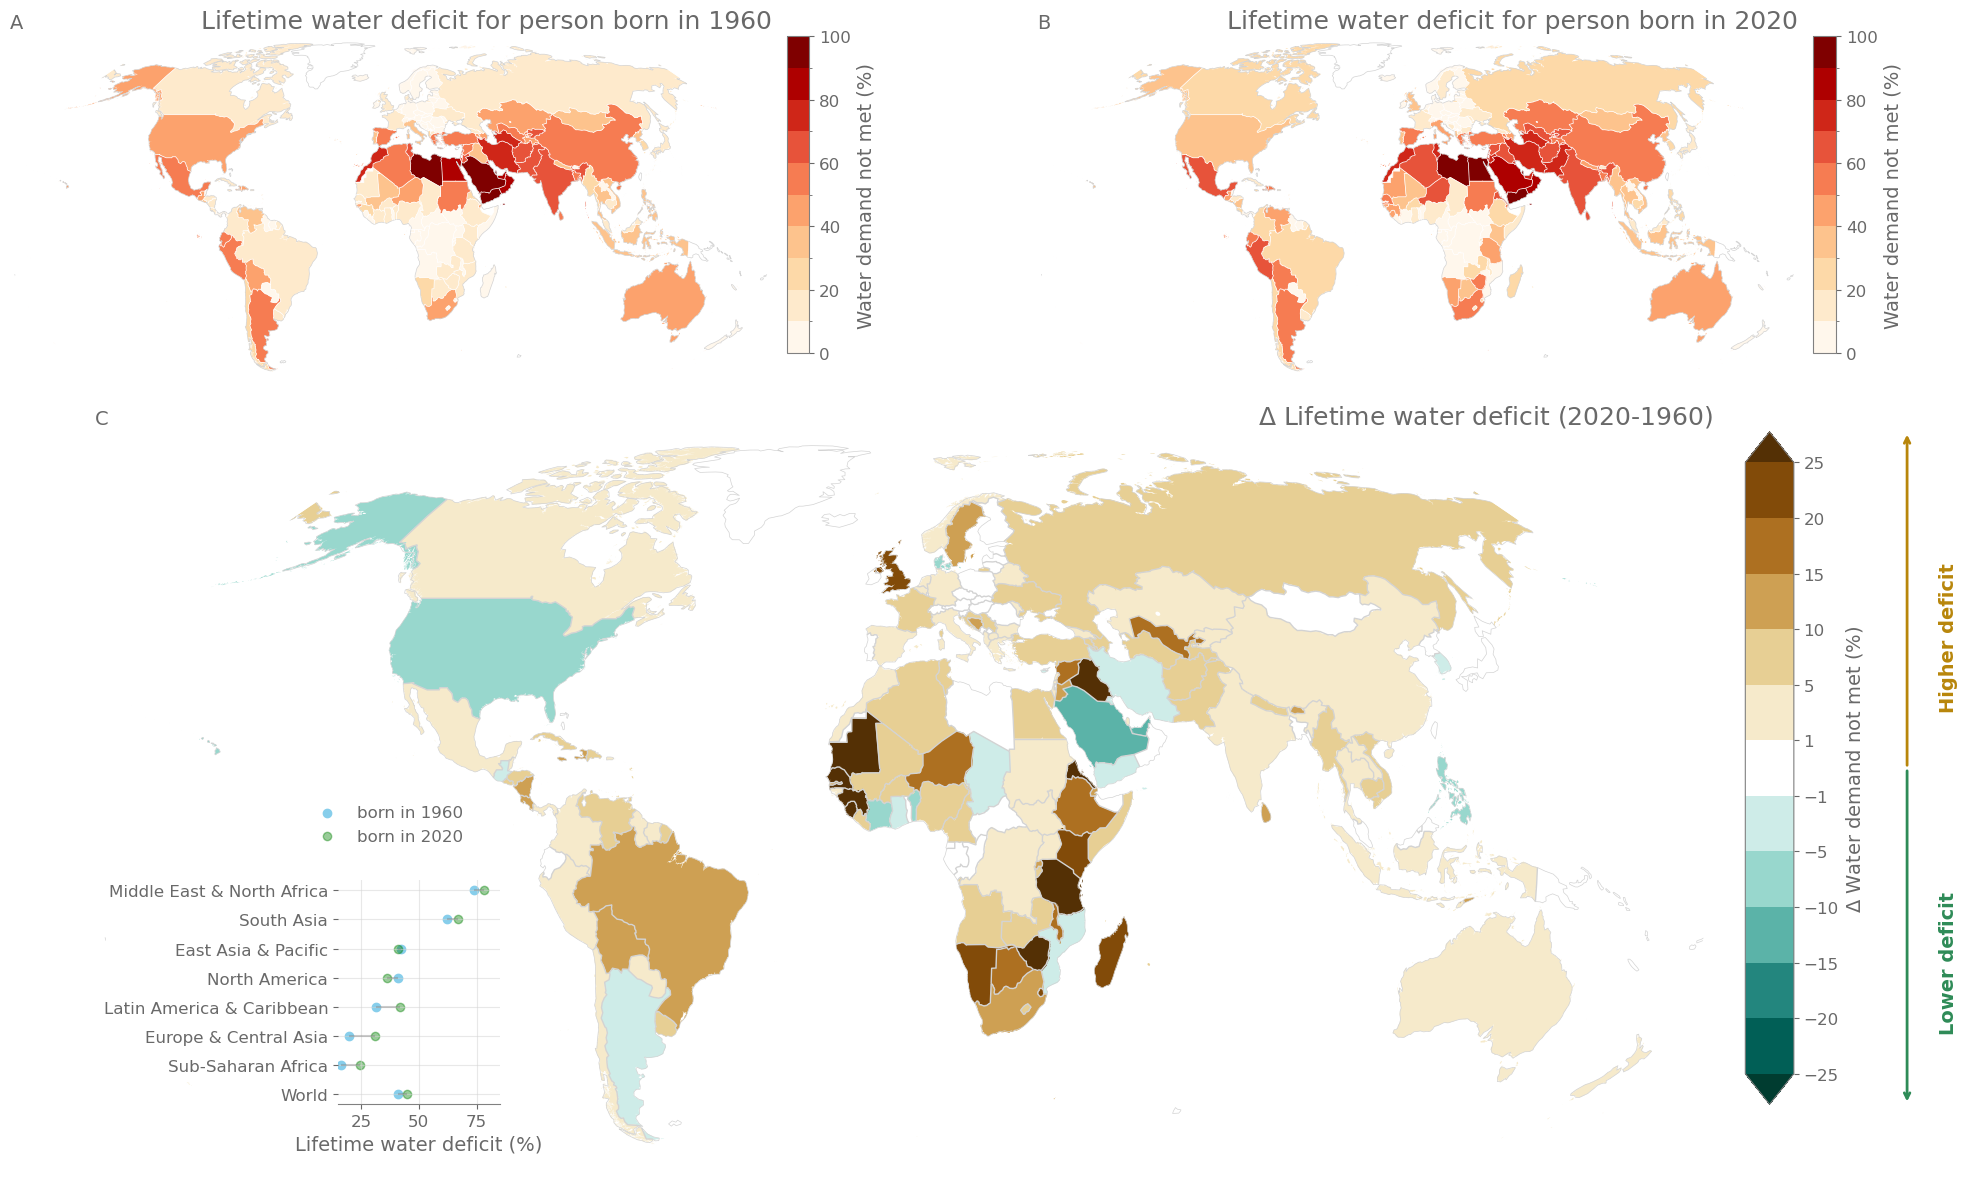

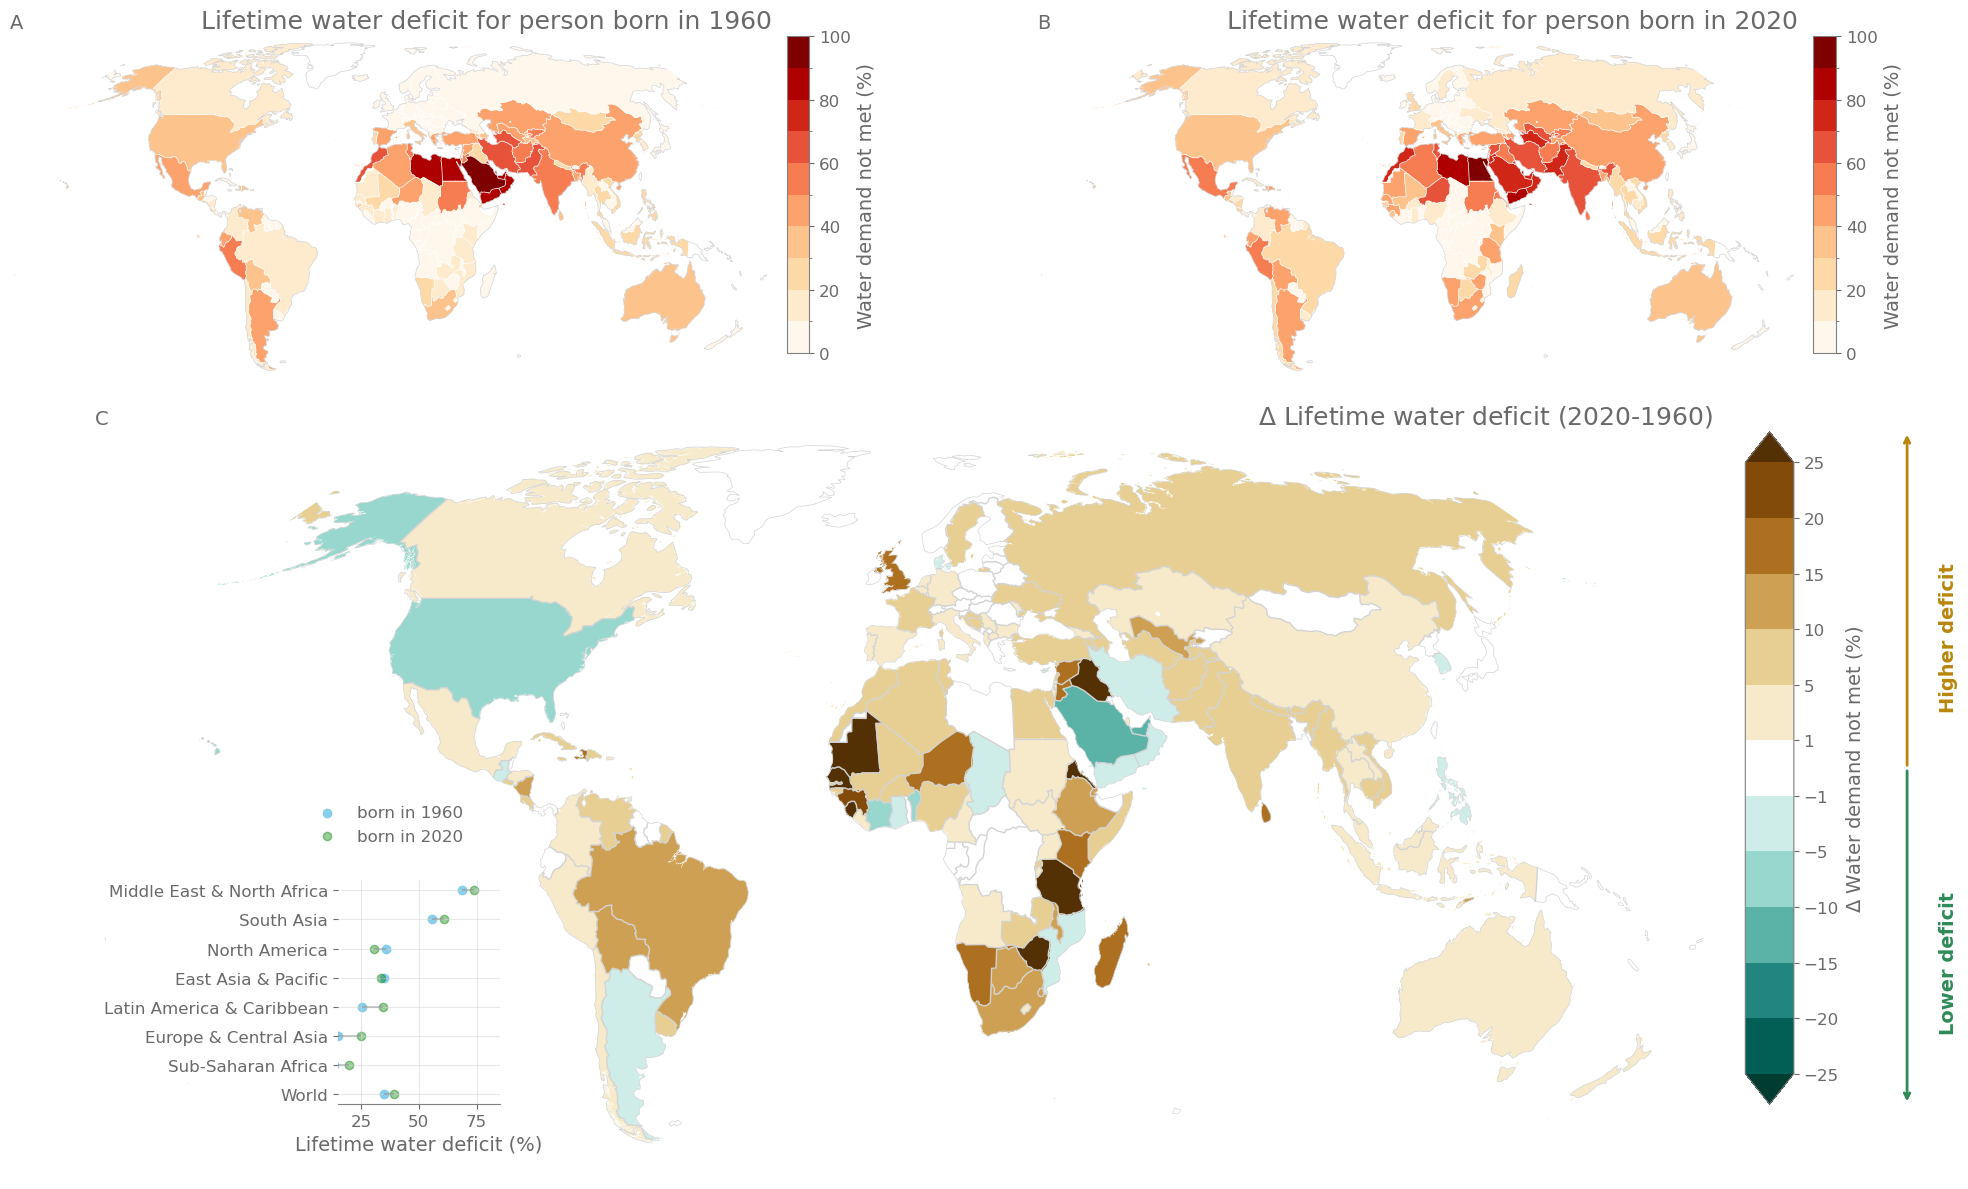

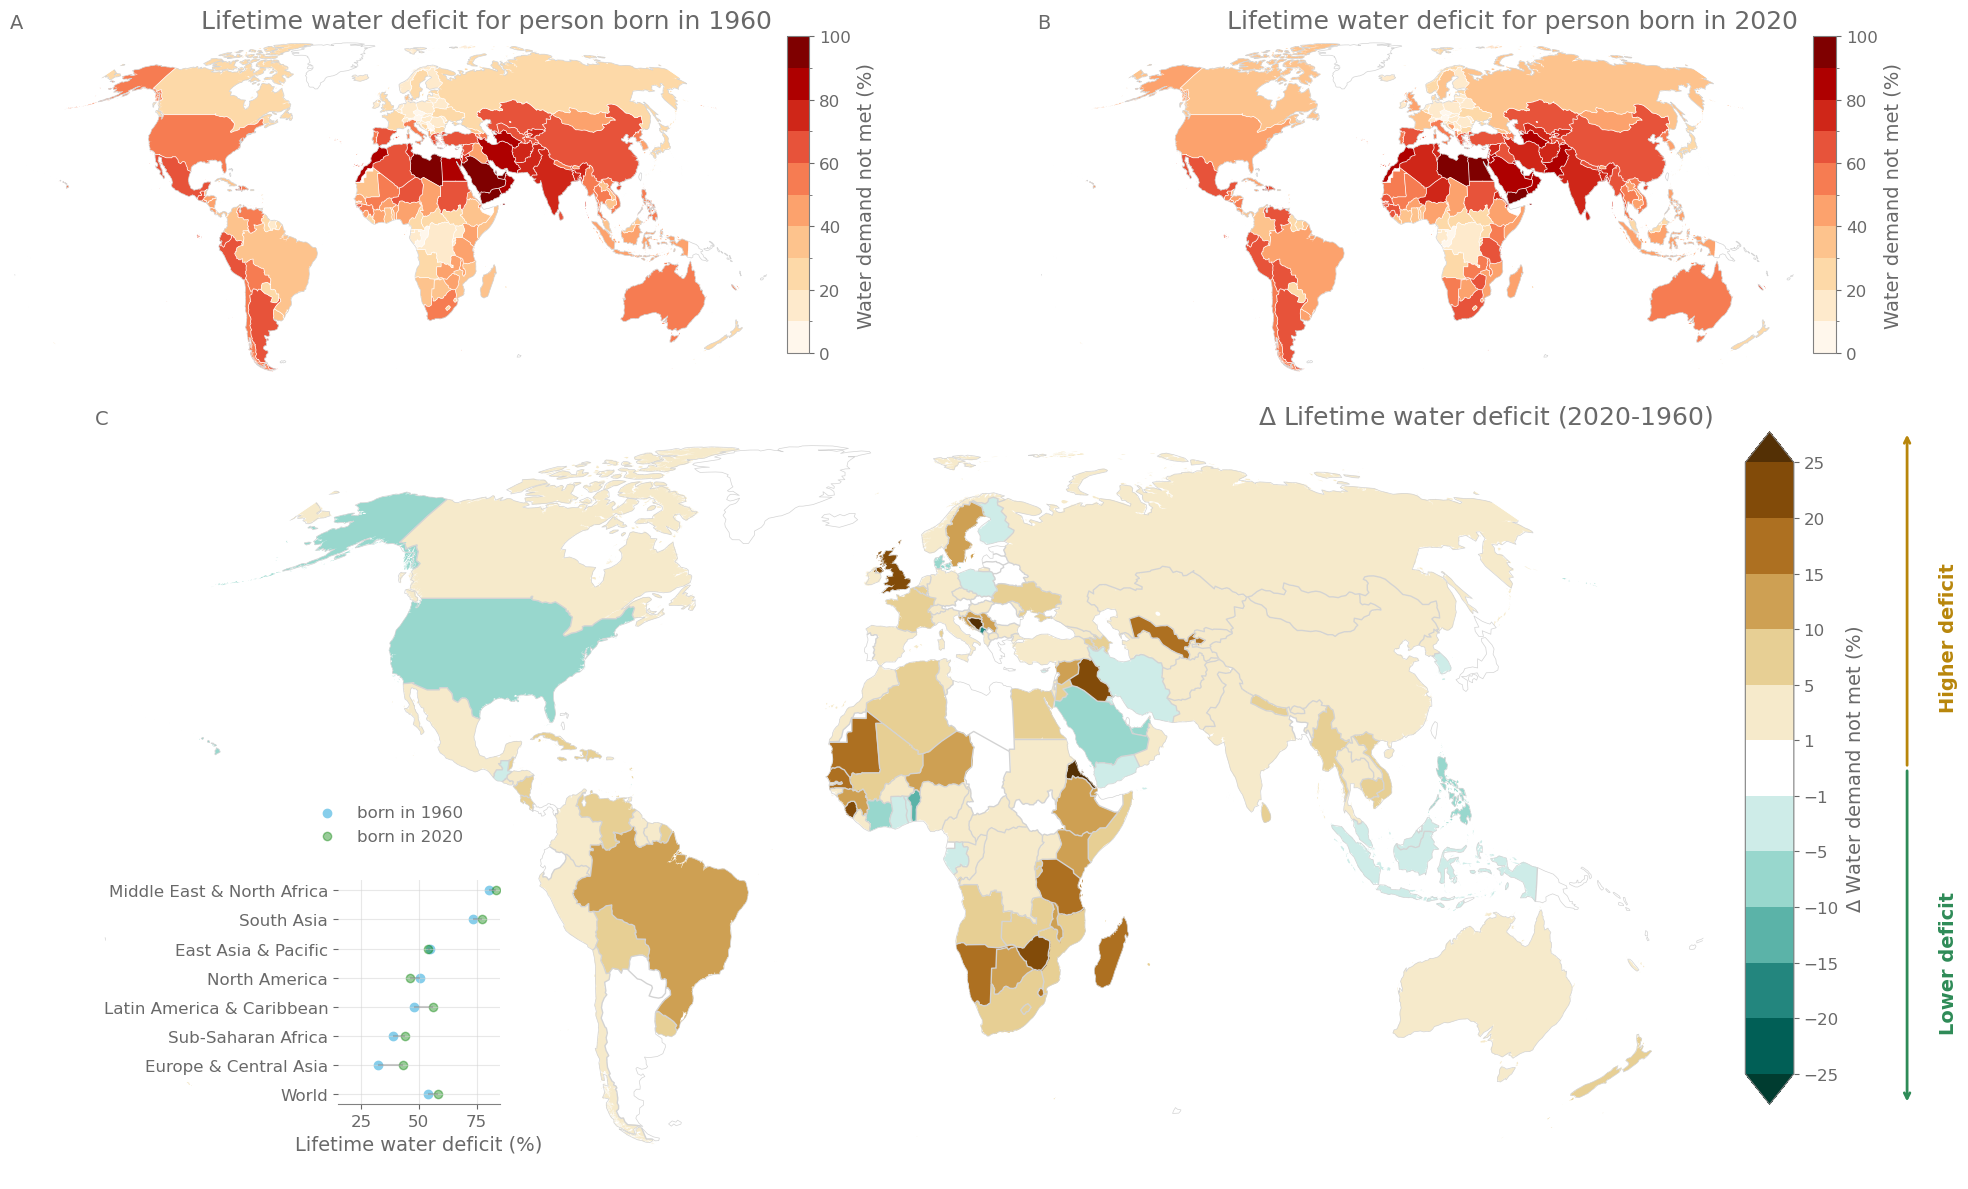

In [8]:
methods = ["", "noEFR", "Tessmann"]
d_df_exposure_birthyear_1960 = {}
d_df_exposure_birthyear_2020 = {}
d_df = {}

for method in methods: 

    # load calculated values 
    flags['extr'] = f'waterdeficit{method}'   
    flags['runs'] = 0          # 0: do not process ISIMIP runs (i.e. load runs pickle)
                                # 1: process ISIMIP runs (i.e. produce and save runs as pickle)
    flags['exposure'] = 0       # 0: do not process ISIMIP runs to compute exposure (i.e. load exposure pickle)
                                # 1: process ISIMIP runs to compute exposure (i.e. produce and save exposure as pickle)

    ds_pct_waterdeficit, ds_pct_waterdeficit_perregion, a, b = calc_lifetime_waterdeficit_EFRmethod(flags, method=method)





    # ------------------------------------------------
    # Create figure and load variable

    fig = plt.figure(figsize=(30,12))

    rcp = 'RCP'
    variable = 'mmm_'+rcp
    da = ds_pct_waterdeficit[variable]


    # colorbar settings for 2 upper plots
    bounds = np.array([0,10,20,30,40,50,60,70,80,90,100])
    legend_label = "Water demand not met (%)"


    # ------------------------------------------------
    # Panel a 
    ax = plt.subplot2grid(shape=(3,3), loc=(0,0), colspan=1, projection=map_proj)

    # ax settings
    ax.axis('off')
    ax.coastlines(color='lightgray',linewidth=0.5)
    ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
    cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

    # data plotting
    birth_year = 1960
    df_1960 = da.sel({'birth_year' : birth_year}).to_dataframe()
    gdf_exposure_birthyear = gdf_country_borders.merge(df_1960[variable], left_index=True, right_on='country')
    d_df_exposure_birthyear_1960[method] = df_1960
    gdf_exposure_birthyear.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='OrRd', legend_kwds={'label': legend_label}, vmax=100, transform=ccrs.PlateCarree(), norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256))

    # title settings
    ax.set_title('Lifetime water deficit for person born in '+str(birth_year), loc='right', size=18); 
    ax.set_title(labels[0], loc='left'); 


    # ------------------------------------------------
    # Panel b 
    ax = plt.subplot2grid(shape=(3,3), loc=(0,1), colspan=1, projection=map_proj)

    # ax settings
    ax.axis('off')
    ax.coastlines(color='lightgray',linewidth=0.5)
    ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
    cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

    # data plotting
    birth_year = 2020
    df_2020 = da.sel({'birth_year' : birth_year}).to_dataframe()
    gdf_exposure_birthyear = gdf_country_borders.merge(df_2020[variable], left_index=True, right_on='country')
    d_df_exposure_birthyear_2020[method] = df_2020
    gdf_exposure_birthyear.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='OrRd', legend_kwds={'label': legend_label}, vmax=100, transform=ccrs.PlateCarree(), norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256))

    # title settings
    ax.set_title('Lifetime water deficit for person born in '+str(birth_year), loc='right', size=18); 
    ax.set_title(labels[1], loc='left'); 


    # ------------------------------------------------
    # Panel c 
    ax = plt.subplot2grid(shape=(3,3), loc=(1,0), colspan=2, rowspan=2, projection=map_proj)


    # colorbar settings
    legend_label = '$\Delta$ '+ legend_label
    bounds = np.array([-30,-25,-20,-15,-10,-5,-1,1,5,10,15,20,25,30])
    bounds = np.array([-25,-20,-15,-10,-5,-1,1,5,10,15,20,25])

    cmap_ticks = bounds #np.array([-30,-20,-10,-5,-1,1,5,10,20,30])
    # ax settings
    ax.axis('off')
    ax.coastlines(color='lightgray',linewidth=0.5)
    ax.add_feature(cfeature.BORDERS,color='lightgray',linewidth=1)
    cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

    # Define the colormap and the number of levels
    colormap = plt.cm.get_cmap('BrBG_r')
    num_levels = len(bounds)+1
    # Create the ListedColormap
    new_cmap = ListedColormap(colormap(np.linspace(0, 1, num_levels)))
    # Generate color codes for each level
    color_codes = [colors.to_hex(new_cmap(i)) for i in range(num_levels)]
    color_codes[int(len(color_codes)/2 )] = '#ffffff'

    cmap = ListedColormap(color_codes)

    # data plotting
    d_waterdeficit = (df_2020-df_1960)
    gdf_delta_birthyear = gdf_country_borders.merge(d_waterdeficit, left_index=True, right_on='country')
    gdf_delta_birthyear.plot(ax=ax, column=variable, legend = True,  cmap=cmap,  cax=cax, legend_kwds={'label': legend_label, 'ticks':cmap_ticks, 'aspect': 10 }, vmin=-30, vmax=30, transform=ccrs.PlateCarree(), norm = colors.BoundaryNorm(boundaries=bounds, ncolors=cmap.N, extend='both'))

    # title settings
    ax.set_title('$\Delta$ Lifetime water deficit (2020-1960)',  loc='right', size=18);
    ax.set_title(labels[2], loc='left'); 


    # arrow settings 
    xpos = 1.12
    ypos = 0.55

    ax.annotate('', xy=(xpos,ypos), xycoords=("axes fraction"), xytext=(xpos,ypos+0.45), arrowprops=dict(arrowstyle="<-", color="darkgoldenrod",linewidth=2));
    ax.annotate('', xy=(xpos,ypos), xycoords=("axes fraction"), xytext=(xpos,ypos-0.45), arrowprops=dict(arrowstyle="<-", color="seagreen",linewidth=2));

    xpos_text = xpos+0.02

    ax.annotate('Higher deficit', xy=(xpos_text,ypos+0.35), xycoords=("axes fraction"), xytext=(xpos_text,ypos+0.08), fontsize=14, rotation=90, color="darkgoldenrod", fontweight="semibold"); 
    ax.annotate('Lower deficit', xy=(xpos_text,ypos-0.35), xycoords=("axes fraction"), xytext=(xpos_text,ypos-0.35), fontsize=14, rotation=90, color="seagreen", fontweight="semibold");


    # ------------------------------------------------
    # Panel d - inset lollipop plot

    ax_inset = ax.inset_axes([0.15, 0.1, 0.1, 0.3]) #[x0, y0, width, height]

    var_type = ''#'delta_'
    rcp = 'RCP'
    var = 'mmm_'+var_type+rcp

    # get values
    df_temp = ds_pct_waterdeficit_perregion[var].sel(birth_year=1960).to_dataframe().drop(['birth_year'],axis=1)
    values_2020 = ds_pct_waterdeficit_perregion[var].sel(birth_year=2020).values

    values = np.stack((df_temp.index.values,np.squeeze(df_temp.values),values_2020))
    df_1960 = pd.DataFrame(values.T, columns=['regions','1960','2020'])

    regions_for_plot = regions + ["World"]
    df = df_1960[df_1960["regions"].isin(regions_for_plot)].sort_values(by='1960',ascending=True) 
    # Move "World" to the end
    df = pd.concat([df[df['regions'] == 'World'], df[df['regions'] != 'World'] ], ignore_index=True)
    my_range=range(1,len(df.index)+1)
    d_df[method] = df
    # do plotting 
    ax_inset.hlines(y=my_range, xmin=df['1960'], xmax=df['2020'], color='grey', alpha=0.4)
    ax_inset.scatter(df['1960'], my_range, color='skyblue', alpha=1, label='born in 1960')
    ax_inset.scatter(df['2020'], my_range, color='green', alpha=0.4 , label='born in 2020')

    # plot settings
    ax_inset.legend(bbox_to_anchor=(0.3,1.4), loc='upper center', frameon=False);
    ax_inset.set_yticks(my_range)
    ax_inset.set_yticklabels(df['regions']); 
    ax_inset.spines[['right', 'left', 'top']].set_visible(False)    
    ax_inset.set_xlabel('Lifetime water deficit (%)')
    ax_inset.grid(color='lightgray', alpha=0.5)
    ax_inset.set_xlim((15,85));
    #ax_inset.set_title(labels[3], loc='left'); 


    # ------------------------------------------------
    # Save figurea

    fig.tight_layout()
    plt.savefig(f'figures/maps_{method}.png', bbox_inches='tight',dpi=600)



## Plot differences

In [14]:
delta_noEFR_1960.mean()

birth_year    0.000000
mmm_RCP      -4.532684
dtype: float64

In [15]:
delta_noEFR_2020.mean()

birth_year    0.000000
mmm_RCP      -5.365982
dtype: float64

In [16]:
delta_Tessmann_2020.mean()

birth_year     0.000000
mmm_RCP       15.953032
dtype: float64

In [17]:
delta_Tessmann_1960.mean()

birth_year     0.000000
mmm_RCP       17.791005
dtype: float64

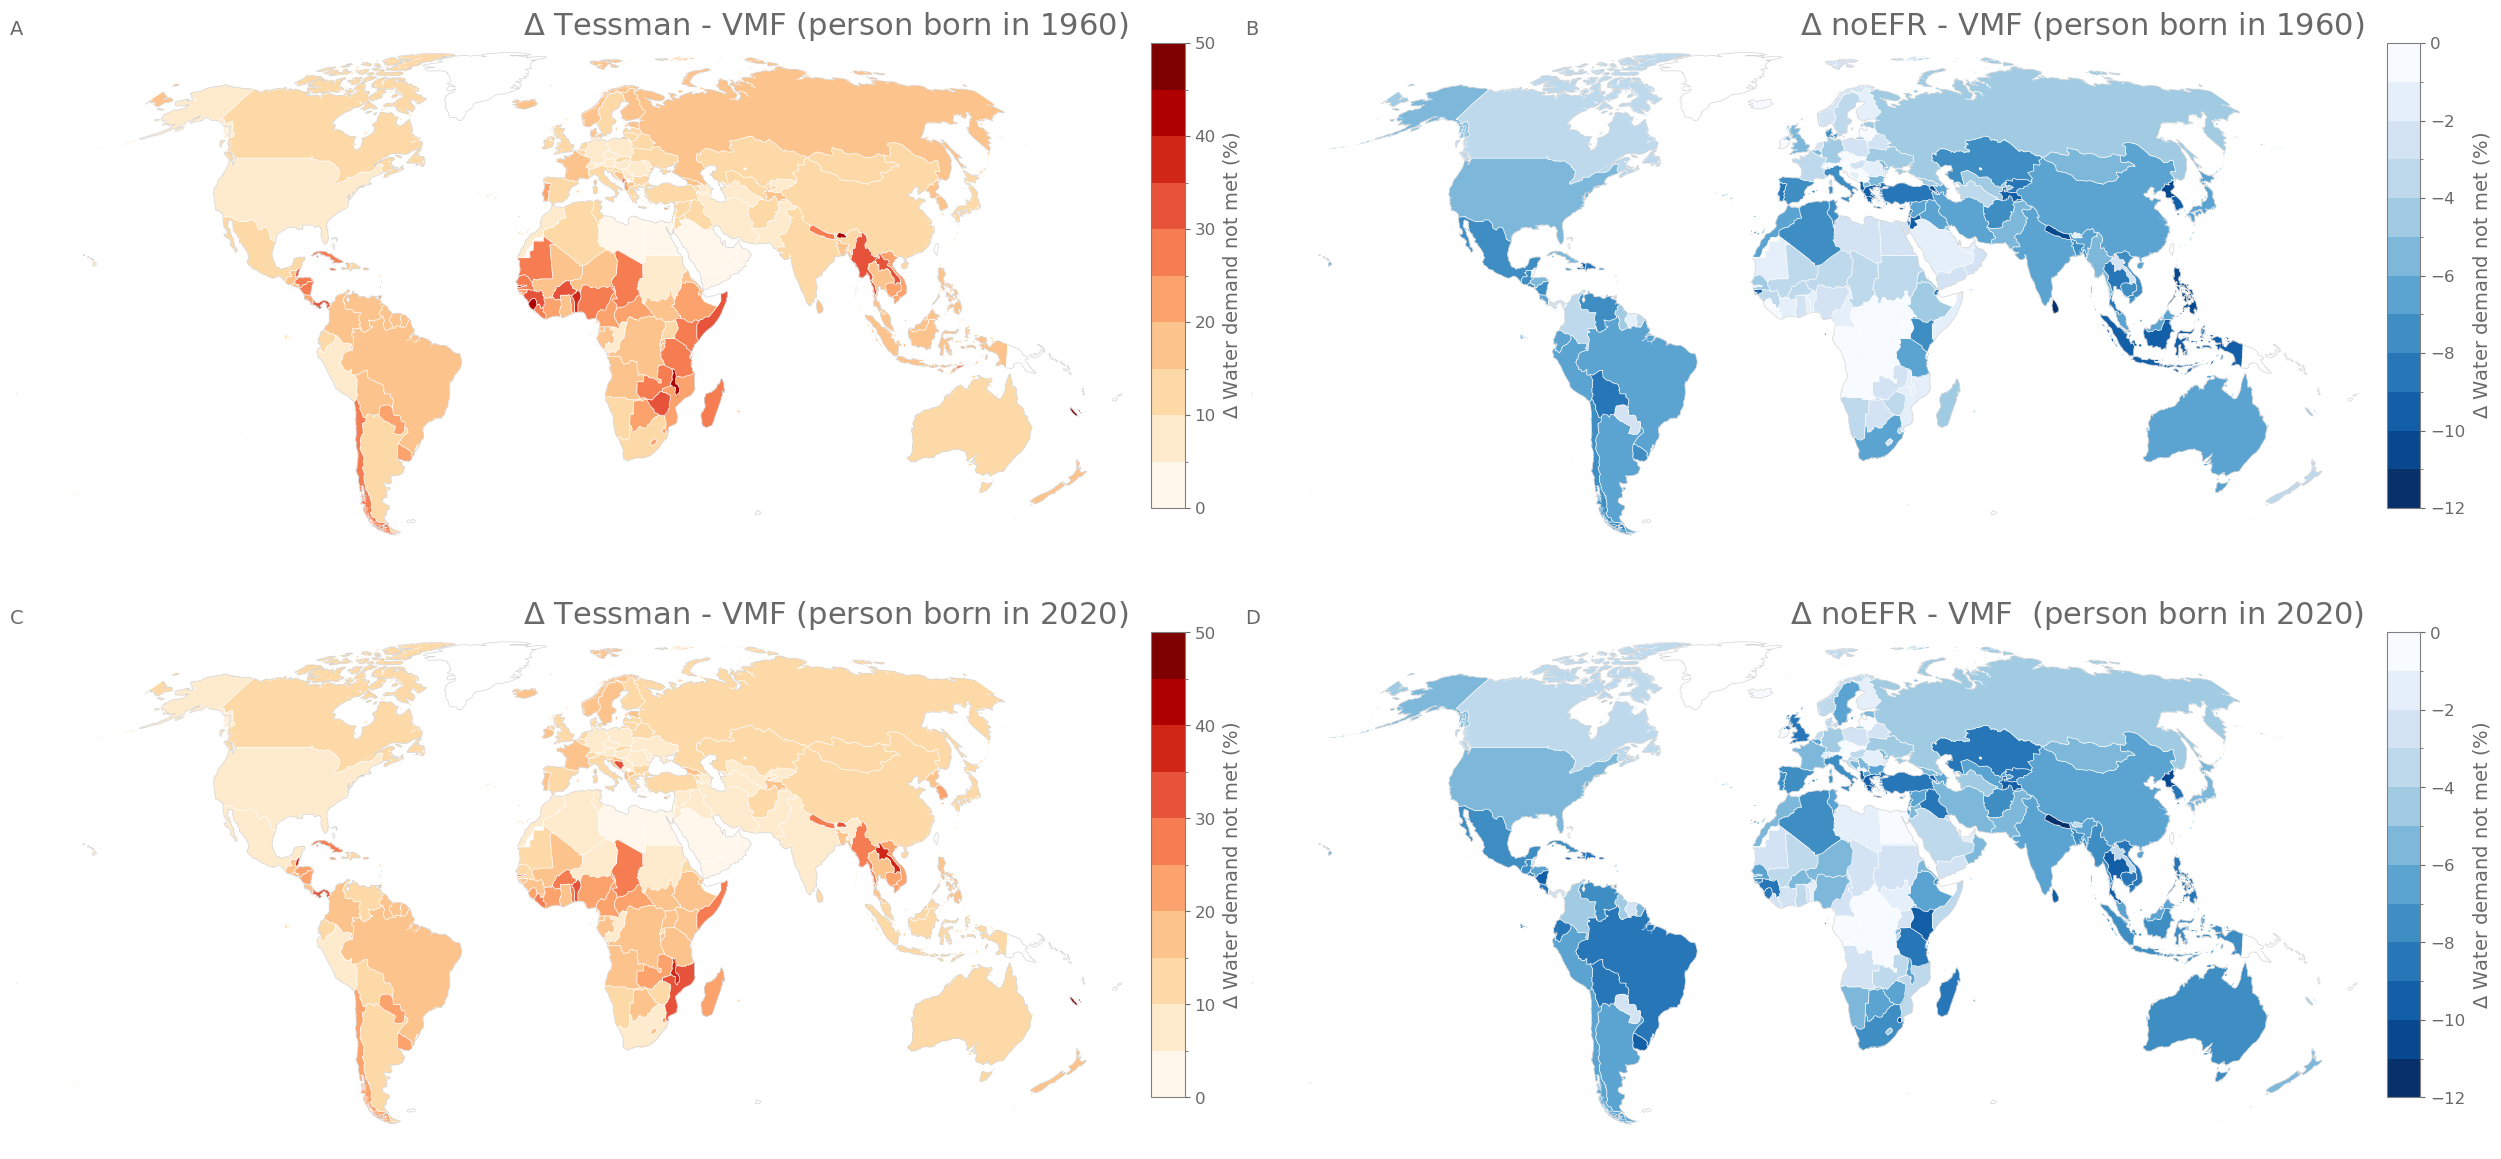

In [12]:
delta_noEFR_1960 = d_df_exposure_birthyear_1960["noEFR"] - d_df_exposure_birthyear_1960[""]
delta_Tessmann_1960 = d_df_exposure_birthyear_1960["Tessmann"] - d_df_exposure_birthyear_1960[""]

fig, axes = plt.subplots(2,2,figsize=(25,12), subplot_kw={'projection':map_proj})
axes = axes.flatten()
ax = axes[0]

# ax settings
ax.axis('off')
ax.coastlines(color='lightgray',linewidth=0.5)
ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

bounds = np.array([0,5,10,15,20,25,30,35,40,45,50])

# Define the colormap and the number of levels
colormap = plt.cm.get_cmap('BrBG_r')
num_levels = len(bounds)+1
# Create the ListedColormap
new_cmap = ListedColormap(colormap(np.linspace(0, 1, num_levels)))
# Generate color codes for each level
color_codes = [colors.to_hex(new_cmap(i)) for i in range(num_levels)]
color_codes[int(len(color_codes)/2 )] = '#ffffff'

cmap = ListedColormap(color_codes)


gdf_delta_Tessmann_1960 = gdf_country_borders.merge(delta_Tessmann_1960[variable], left_index=True, right_on='country')

gdf_delta_Tessmann_1960.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='OrRd', legend_kwds={'label': legend_label}, norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256), transform=ccrs.PlateCarree())

ax.set_title('$\Delta$ Tessman - VMF (person born in 1960)', loc='right', size=22); 
ax.set_title(labels[0], loc='left'); 

ax = axes[1]
# ax settings
ax.axis('off')
ax.coastlines(color='lightgray',linewidth=0.5)
ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

bounds = np.array([-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0])

# Define the colormap and the number of levels
colormap = plt.cm.get_cmap('BrBG_r')
num_levels = len(bounds)+1
# Create the ListedColormap
new_cmap = ListedColormap(colormap(np.linspace(0, 1, num_levels)))
# Generate color codes for each level
color_codes = [colors.to_hex(new_cmap(i)) for i in range(num_levels)]
color_codes[int(len(color_codes)/2 )] = '#ffffff'


gdf_delta_noEFR_1960 = gdf_country_borders.merge(delta_noEFR_1960[variable], left_index=True, right_on='country')

gdf_delta_noEFR_1960.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='Blues_r', legend_kwds={'label': legend_label}, norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256), transform=ccrs.PlateCarree())

# title settings
ax.set_title('$\Delta$ noEFR - VMF (person born in 1960)', loc='right', size=22); 
ax.set_title(labels[1], loc='left'); 



delta_noEFR_2020 =   d_df_exposure_birthyear_2020["noEFR"] - d_df_exposure_birthyear_2020[""]
delta_Tessmann_2020 =   d_df_exposure_birthyear_2020["Tessmann"] - d_df_exposure_birthyear_2020[""]

ax = axes[2]

# ax settings
ax.axis('off')
ax.coastlines(color='lightgray',linewidth=0.5)
ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

bounds = np.array([0,5,10,15,20,25,30,35,40,45,50])

# Define the colormap and the number of levels
colormap = plt.cm.get_cmap('BrBG_r')
num_levels = len(bounds)+1
# Create the ListedColormap
new_cmap = ListedColormap(colormap(np.linspace(0, 1, num_levels)))
# Generate color codes for each level
color_codes = [colors.to_hex(new_cmap(i)) for i in range(num_levels)]
color_codes[int(len(color_codes)/2 )] = '#ffffff'

cmap = ListedColormap(color_codes)


gdf_delta_Tessmann_2020= gdf_country_borders.merge(delta_Tessmann_2020[variable], left_index=True, right_on='country')

gdf_delta_Tessmann_2020.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='OrRd', legend_kwds={'label': legend_label}, norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256), transform=ccrs.PlateCarree())

ax.set_title('$\Delta$ Tessman - VMF (person born in 2020)', loc='right', size=22); 
ax.set_title(labels[2], loc='left'); 

ax = axes[3]
# ax settings
ax.axis('off')
ax.coastlines(color='lightgray',linewidth=0.5)
ax.add_feature(cfeature.BORDERS,color='white',linewidth=0.5)
cax = ax.inset_axes((1.02, 0.1, 0.03, 0.9)); #make a color bar axis

bounds = np.array([-12,-11,-10,-9,-8,-7,-6,-5,-4,-3,-2,-1,0])

# Define the colormap and the number of levels
colormap = plt.cm.get_cmap('BrBG_r')
num_levels = len(bounds)+1
# Create the ListedColormap
new_cmap = ListedColormap(colormap(np.linspace(0, 1, num_levels)))
# Generate color codes for each level
color_codes = [colors.to_hex(new_cmap(i)) for i in range(num_levels)]
color_codes[int(len(color_codes)/2 )] = '#ffffff'


gdf_delta_noEFR_2020 = gdf_country_borders.merge(delta_noEFR_2020[variable], left_index=True, right_on='country')

gdf_delta_noEFR_2020.plot(ax=ax, column=variable, cax=cax, legend = True,  cmap='Blues_r', legend_kwds={'label': legend_label}, norm = colors.BoundaryNorm(boundaries=bounds, ncolors=256), transform=ccrs.PlateCarree())

# title settings
ax.set_title('$\Delta$ noEFR - VMF  (person born in 2020)', loc='right', size=22); 
ax.set_title(labels[3], loc='left'); 

fig.tight_layout()
plt.savefig(f'figures/maps_EFRmethods_deltas.png', bbox_inches='tight',dpi=600)



In [51]:
for method in d_df.keys(): 
    df = d_df[method]
    df.to_csv(f'figures/lifetime_waterdeficit_perregion_{method}.csv', index=False)


### Values

In [16]:
# average lifetime water deficit global 1960 birth cohort
print(f"Global average lifetime water deficit for 1960 birth cohort: {df.loc[df['regions'] == 'World', ['1960']].values[0][0]:.0f} %")

# average lifetime water deficit global 2020 birth cohort
print(f"Global average lifetime water deficit for 2020 birth cohort: {df.loc[df['regions'] == 'World', ['2020']].values[0][0]:.0f} %")

print(f"Difference 2020 and 1960 birth cohort: {df.loc[df['regions'] == 'World', ['2020']].values[0][0] - df.loc[df['regions'] == 'World', ['1960']].values[0][0] :.0f} %")

print(" ")


print("Lifetime water deficit for selected countries for 1960 birth cohort:")
countries_to_extract = ["Egypt", "Yemen", "Libya", "Saudi Arabia", "Oman", "United Arab Emirates"]
df_1960_countries = da.sel({'birth_year' : 1960}).to_dataframe()
df_2020_countries = da.sel({'birth_year' : 2020}).to_dataframe()
for country in countries_to_extract:
    print(f"{country}: {df_1960_countries.loc[country, 'mmm_RCP']:.0f} %")

print(" ")


print("Generational difference in lifetime water deficit for selected countries (2020-1960):")
df_diff = df_2020_countries - df_1960_countries
countries_to_extract = ["Sierra Leone", "Zimbabwe","Eritrea","Mauritania", "United Arab Emirates", "Saudi Arabia", "Denmark", "Philippines"]
for country in countries_to_extract:
    print(f"{country}: {df_diff.loc[country, 'mmm_RCP']:.0f} %")


print(" ")

print("Generational difference in lifetime water deficit for selected regions (2020-1960):")
regions_to_extract = [ 'Latin America & Caribbean',  'Europe & Central Asia',  'Sub-Saharan Africa']
for region in regions_to_extract:
    diff_region = (df.loc[df['regions'] == region, ['2020']].values - df.loc[df['regions'] == region, ['1960']].values)[0][0]
    print(f"{region}: {diff_region:.0f} %")

Global average lifetime water deficit for 1960 birth cohort: 41 %
Global average lifetime water deficit for 2020 birth cohort: 45 %
Difference 2020 and 1960 birth cohort: 4 %
 
Lifetime water deficit for selected countries for 1960 birth cohort:
Egypt: 88 %
Yemen: 92 %
Libya: 91 %
Saudi Arabia: 92 %
Oman: 84 %
United Arab Emirates: 90 %
 
Generational difference in lifetime water deficit for selected countries (2020-1960):
Sierra Leone: 43 %
Zimbabwe: 40 %
Eritrea: 36 %
Mauritania: 33 %
United Arab Emirates: -11 %
Saudi Arabia: -11 %
Denmark: -6 %
Philippines: -7 %
 
Generational difference in lifetime water deficit for selected regions (2020-1960):
Latin America & Caribbean: 11 %
Europe & Central Asia: 11 %
Sub-Saharan Africa: 7 %


## BARPLOT
For water scarcity
Main script for plotting, does analysis based on script

## Load water deficit values and get cohort size per country

Loading processed country and region data
Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures


NameError: name 'BE_colors' is not defined

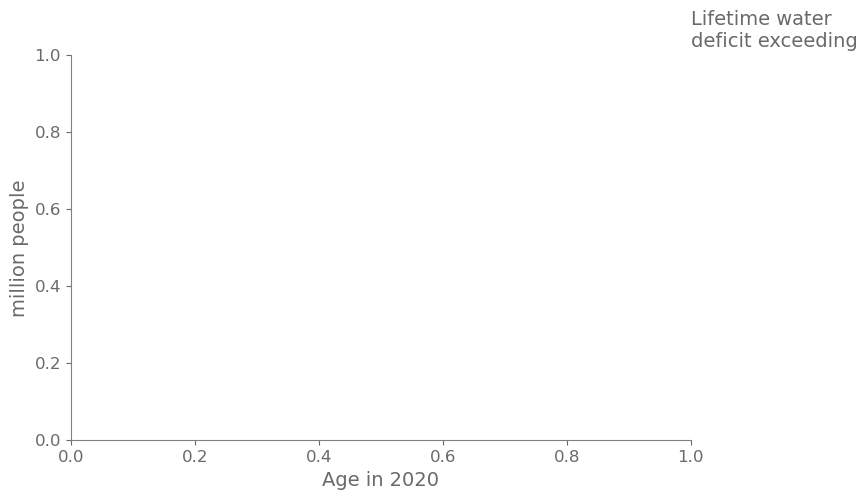

In [11]:
methods = ["noEFR", "Tessmann"]

for method in methods: 

    # load calculated values 
    flags['extr'] = f'waterdeficit{method}' 
    # Load water deficit values 
    ds_pct_waterdeficit, ds_pct_waterdeficit_perregion, a, b = calc_lifetime_waterdeficit(flags)

    # get cohort size per country
    data = {
        country: d_countries['cohort_size'][country].loc[2020] * 1000
        for country in d_countries['cohort_size']
    }

    df_cohortsize_percountry_2020 = pd.DataFrame(data)

    # Define cohort classes and labels
    cohort_classes       = [[0,9], [10,19], [20,29], [30,39], [40,49], [50,59]]
    cohort_classes_label = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59']

    # get the cohortsizes per birth year, per region
    df_pop_perregion = get_cohortsizes_perregion()

    # group the cohorts into classes (calculate sum of # people within cohorts)
    df_cohort_grouped = group_cohorts_into_classes(df_pop_perregion, cohort_classes, cohort_classes_label).iloc[::-1]

    # calculate share of every cohort class for every region
    cohort_grouped_share = df_cohort_grouped.div(df_cohort_grouped.sum(axis=0), axis=1)

    # calculate country weights based on total region population
    d_country_weights = {region: df_countries[df_countries['region']==region]['population'].div(float(df_countries.groupby('region').sum().loc[region]['population'])) for region in regions}
    d_country_weights['World'] = df_countries['population'] / df_countries['population'].sum()


    # convert data array into dataframe for plotting
    var = 'mmm_RCP'
    df_pct_waterdeficit = pd.DataFrame(ds_pct_waterdeficit[var].values, columns = ds_pct_waterdeficit[var]['country'], index = df_cohortsize_percountry_2020.index)

    var = 'lqntl_RCP'
    df_pct_waterdeficit_lqntl = pd.DataFrame(ds_pct_waterdeficit[var].values, columns = ds_pct_waterdeficit[var]['country'], index = df_cohortsize_percountry_2020.index)

    var = 'uqntl_RCP'
    df_pct_waterdeficit_uqntl = pd.DataFrame(ds_pct_waterdeficit[var].values, columns = ds_pct_waterdeficit[var]['country'], index = df_cohortsize_percountry_2020.index)


    # per birth year and country calculate number of people above certain lifetime water deficit threshold and then calculate weighted average per region and globally

    thresholds = [50,75,90] # %
    thresholds = [50,60,70,80,90] # %

    d_npeople_ot = {}

    d_cohortsize_percountry_overthreshold = {}

    for threshold in thresholds:

        df_cohortsize_percountry_overthreshold = df_cohortsize_percountry_2020.where(df_pct_waterdeficit > threshold)
        
        d_cohortsize_percountry_overthreshold[threshold] = df_cohortsize_percountry_overthreshold

        df_npeople_ot_perbirthyear = pd.DataFrame()
        
        # group the countries by region
        for region in regions: 

            countries_in_region = list(df_countries[df_countries['region'] == region].index)

            # calculate the number of people with lifetime water deficit over the threshold per region (based on country average values)
            # THIS CALCULATION SHOULD BE THE WEIGHTED SUM
            # df_npeople_ot_perbirthyear[region] = (df_cohortsize_percountry_overthreshold[countries_in_region] * d_country_weights[region]).sum(axis =1)
            
            # this should not be weighted but just be summed? 
            df_npeople_ot_perbirthyear[region] = (df_cohortsize_percountry_overthreshold[countries_in_region]).sum(axis =1)
            

        # for the world, weighted based on all countries (not average per region!!!!)
        df_npeople_ot_perbirthyear['World'] =  (df_cohortsize_percountry_overthreshold * d_country_weights['World']).sum(axis =1)
        df_npeople_ot_perbirthyear['World'] =  (df_cohortsize_percountry_overthreshold).sum(axis =1)


        # group number of people per cohort 
        d_npeople_ot[threshold] = group_cohorts_into_classes(df_npeople_ot_perbirthyear, cohort_classes, cohort_classes_label).iloc[::-1]

    # turn dictionary into dataset  
    ds_npeople = xr.concat(
        [xr.DataArray(v).rename({'dim_0':'cohort_class','dim_1':'region'}) for v in d_npeople_ot.values()],

        dim='threshold').assign_coords({'threshold':list(d_npeople_ot.keys())})

        # million people
    thresholds_to_show = [50, 60, 70, 80]

    region = 'World'
    # define burning ember colors

    fig, ax = plt.subplots(1,1, figsize=(8,5))
    ax.set_ylabel('million people')
    ax.set_xlabel('Age in 2020');
    #ax.set_title('Number of people per age cohort worldwide',loc='right')
    ax.spines[['right', 'top']].set_visible(False)    

    ax.set_title('Lifetime water\ndeficit exceeding',  y=1.0, x=1,loc='left');

    # get people per threshold for region

    df_toplot =  pd.DataFrame(ds_npeople.sel(region=region).values.T, index=  ds_npeople.cohort_class.values ,columns =ds_npeople.threshold.values) *1e-6

    df_toplot.iloc[:,0].plot.bar(ax=ax, color=BE_colors[0], label=str(df_toplot.keys()[0])+' %', rot=0)

    for n in range(1,len(thresholds_to_show)):
        df_toplot.iloc[:,n].plot.bar(ax=ax, color=BE_colors[n],  label=str(df_toplot.keys()[n])+' %', alpha=0.5, rot=0)
        
    leg = ax.legend(bbox_to_anchor=(1,1), loc="upper left",frameon=False)    

    for lh in leg.legend_handles: lh.set_alpha(1)


    # get people multiplication factor
    pmf = df_toplot/df_toplot.iloc[0,:]

    n=0
    for j,p in enumerate(ax.patches):
        if j < 6: 
            ax.annotate('x '+str(np.round(pmf.iloc[:,0].values,1)[j]), (p.get_x() + 0.07, p.get_height() + 15))
        elif j >= 6 and j < 12: 
            
            ax.annotate('x '+str(np.round(pmf.iloc[:,1].values,1)[j-6]), (p.get_x() + 0.07, p.get_height() + 15))
        elif j >= 12 and j < 18: 
            
            ax.annotate('x '+str(np.round(pmf.iloc[:,2].values,1)[j-12]), (p.get_x() + 0.07, p.get_height() + 10))
        elif j > 19 and j < 24: 
            
            ax.annotate('x '+str(np.round(pmf.iloc[:,3].values,1)[j-18]), (p.get_x() + 0.07, p.get_height() + 15))
            
    plt.savefig(f'figures/barplot_{method}.png', bbox_inches='tight',dpi=600)


## Values

In [ ]:
# get values
pop_50pct_under60 = d_npeople_ot[50]['World'].sum()
total_pop_under60 = df_cohort_grouped['World'].sum()

pct_worldpop_50_waterdeficit = pop_50pct_under60 / total_pop_under60 *100 

print('Number of people 60 and under experiencing 50% lifetime water deficit')
print(pop_50pct_under60)
print()

print('Percent of world population')
print(pct_worldpop_50_waterdeficit)
print()

Number of people 60 and under experiencing 50% lifetime water deficit
3738689008.0

Percent of world population
55.84284628359377



In [ ]:
df_toplot.loc[age_category,threshold]

np.float64(33.38342)

In [ ]:
thresholds = [50, 50, 80, 80,90,90]
age_categories = ['50-59', '0-9','50-59', '0-9', '50-59', '0-9']

for threshold,age_category in zip(thresholds, age_categories):
    print(f"{df_toplot.loc[age_category,threshold]:.0f} million people aged {age_category} are expected to experience {threshold}% lifetime water deficit")
    print(f"{df_toplot.loc[age_category,threshold] / (df_cohort_grouped.loc[age_category,'World']*1e-6) * 100:.0f}% of the world cohort")
    print(" ")
    
print(f"multiplication factor 90%: {df_toplot.loc[ '0-9',90]/df_toplot.loc['50-59',90]:.1f}")

466 million people aged 50-59 are expected to experience 50% lifetime water deficit
56% of the world cohort
 
706 million people aged 0-9 are expected to experience 50% lifetime water deficit
53% of the world cohort
 
16 million people aged 50-59 are expected to experience 80% lifetime water deficit
2% of the world cohort
 
40 million people aged 0-9 are expected to experience 80% lifetime water deficit
3% of the world cohort
 
10 million people aged 50-59 are expected to experience 90% lifetime water deficit
1% of the world cohort
 
33 million people aged 0-9 are expected to experience 90% lifetime water deficit
3% of the world cohort
 
multiplication factor 90%: 3.3


In [ ]:
33/10

3.3

In [57]:
ds_waterdeficit_perregion.sel(region='Middle East & North Africa')["mmm_RCP"].sel(birth_year=1960).values


array(581251.1038626)

In [60]:
(ds_waterdeficit_perregion.sel(region='Middle East & North Africa')["mmm_RCP"].sel(birth_year=2020).values)/(ds_waterdeficit_perregion.sel(region='Middle East & North Africa')["mmm_RCP"].sel(birth_year=1960).values)


np.float64(33.765443106704744)

In [62]:
(ds_withdrawal_perregion.sel(region='Middle East & North Africa')["mmm_RCP"].sel(birth_year=2020).values)/(ds_withdrawal_perregion.sel(region='Middle East & North Africa')["mmm_RCP"].sel(birth_year=1960).values)


np.float64(35.28647417267329)

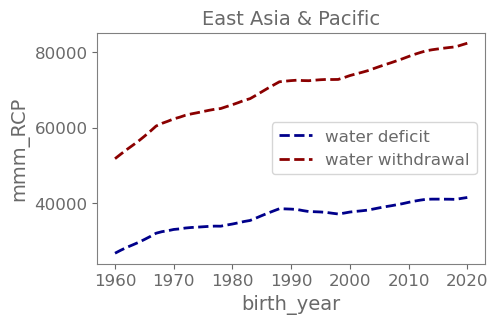

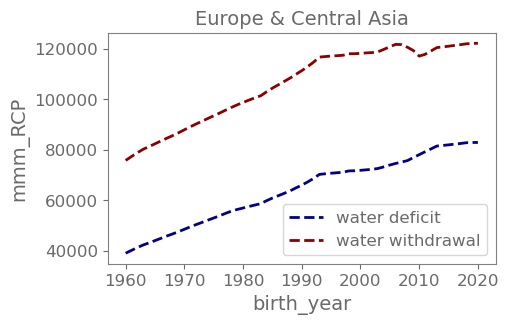

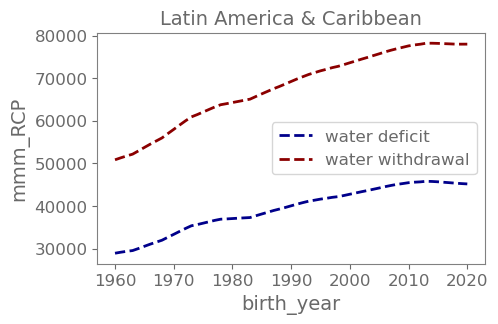

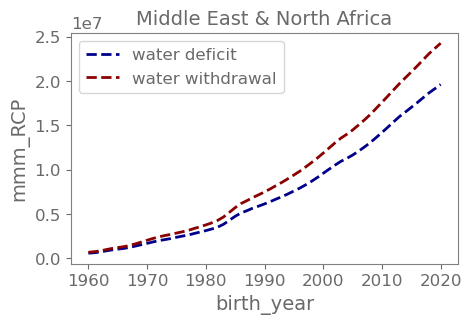

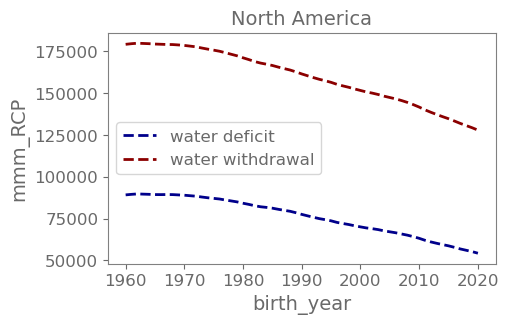

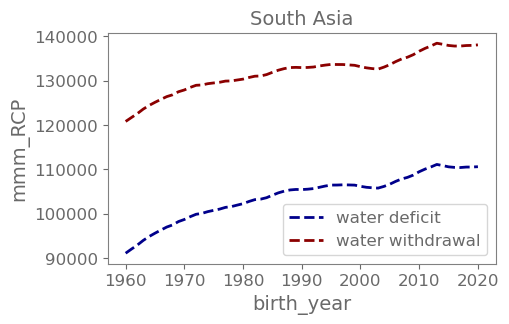

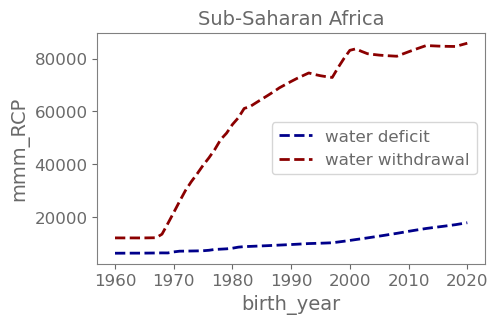

In [36]:
regions = ['East Asia & Pacific', 'Europe & Central Asia', 'Latin America & Caribbean', 
       'Middle East & North Africa', 'North America', 'South Asia',
       'Sub-Saharan Africa']

for region in regions:
    
       fig, ax = plt.subplots(figsize=(5, 3))
       ds_waterdeficit_perregion.sel(region=region)["mmm_RCP"].plot(ax=ax,label=(f"water deficit"), color='darkblue', linewidth=2, linestyle='--')

       ds_withdrawal_perregion.sel(region=region)["mmm_RCP"].plot(ax = ax, label="water withdrawal", color='darkred', linewidth=2, linestyle='--')
       ax.set_title(region)
       plt.legend()

In [54]:
birth_year = 1960
waterdeficit = ds_waterdeficit_perregion.where(ds_waterdeficit_perregion.region.isin(regions), drop=True)["mmm_RCP"].sel(birth_year=birth_year).sum()
print(f"water deficit {birth_year} summed for all regions {waterdeficit.values:.0f} m3/person")

birth_year = 2020
waterdeficit = ds_waterdeficit_perregion.where(ds_waterdeficit_perregion.region.isin(regions), drop=True)["mmm_RCP"].sel(birth_year=birth_year).sum()
print(f"water deficit {birth_year} summed for all regions {waterdeficit.values:.0f} m3/person")

print(" ")

birth_year = 1960
waterdeficit = ds_withdrawal_perregion.where(ds_withdrawal_perregion.region.isin(regions), drop=True)["mmm_RCP"].sel(birth_year=birth_year).sum()
print(f"water withdrawal {birth_year} summed for all regions {waterdeficit.values:.0f} m3/person")

birth_year = 2020
waterdeficit = ds_withdrawal_perregion.where(ds_withdrawal_perregion.region.isin(regions), drop=True)["mmm_RCP"].sel(birth_year=birth_year).sum()
print(f"water withdrawal {birth_year} summed for all regions {waterdeficit.values:.0f} m3/person")

water deficit 1960 summed for all regions 862339 m3/person
water deficit 2020 summed for all regions 19978358 m3/person
 
water withdrawal 1960 summed for all regions 1178409 m3/person
water withdrawal 2020 summed for all regions 24906422 m3/person


In [ ]:
regions = ['East Asia & Pacific', 'Europe & Central Asia', 'Latin America & Caribbean', 
       'Middle East & North Africa', 'North America', 'South Asia',
       'Sub-Saharan Africa']

for region in regions:
    
       print(ds_waterdeficit_perregion.where(ds_waterdeficit_perregion.region.isin(regions))["mmm_RCP"]

       ds_withdrawal_perregion.sel(region=region)["mmm_RCP"].sum()

In [ ]:
print(f"Total water withdrawal and demand")

calc_lifetime_waterdeficit_absolute

flags['extr'] = 'waterdeficit'   # 0: all
ds_waterdeficit, ds_waterdeficit_perregion, d_waterdeficit_allruns = do_lifetime_analysis(flags)


# load lifetime waterwithdrawal
flags['extr'] = 'withdrawal'   # 0: all
ds_withdrawal, ds_withdrawal_perregion, d_withdrawal_allruns = do_lifetime_analysis(flags)


waterdeficit_m3_world = ds_waterdeficit_perregion.sel(region='World').sel(birth_year=1960)["mmm_RCP"].values
waterdemand_m3_world = ds_withdrawal_perregion.sel(region='World').sel(birth_year=1960)["mmm_RCP"].values
print(" ")
print(f"World water deficit 1960 birth cohort: {waterdeficit_m3_world:.0f} m³")
print(f"World water demand 1960 birth cohort: {waterdemand_m3_world:.0f} m³")
print(" ")
waterdeficit_m3_world_2020 = ds_waterdeficit_perregion.sel(region='World').sel(birth_year=2020)["mmm_RCP"].values
waterdemand_m3_world_2020 = ds_withdrawal_perregion.sel(region='World').sel(birth_year=2020)["mmm_RCP"].values
print(" ")
print(f"World water deficit 2020 birth cohort: {waterdeficit_m3_world_2020:.0f} m³")
print(f"World water demand 2020 birth cohort: {waterdemand_m3_world_2020:.0f} m³")

print(" ")
print(f"Difference in world water deficit 2020-1960 birth cohort: {waterdeficit_m3_world_2020-waterdeficit_m3_world:.0f} m³")


Total water withdrawal and demand
Loading processed country and region data


Loading processed isimip data
Loading processed exposures
Loading processed country and region data
Loading processed isimip data
Loading processed exposures
 
World water deficit 1960 birth cohort: 68915 m³
World water demand 1960 birth cohort: 103422 m³
 
 
World water deficit 2020 birth cohort: 1438202 m³
World water demand 2020 birth cohort: 1807920 m³
 
Difference in world water deficit 2020-1960 birth cohort: 1369287 m³


In [85]:
def calc_pctwaterdeficit_perregion_perrun(d_pct_waterdeficit_perrun):

    d_regions = pd.read_pickle(open('./data/pickles/region_info.pkl', 'rb'))
    d_cohort_weights_regions = d_regions['cohort_size']
    
    d_countries = pd.read_pickle(open('./data/pickles/country_info.pkl', 'rb'))
    df_countries = d_countries['info_pop']
    
    d_exposure_perregion_perrun = {}

    for i in d_pct_waterdeficit_perrun.keys():

        d_exposure_perregion = {}


        for region in d_cohort_weights_regions.keys():

            member_countries = get_countries_of_region(region, df_countries)  

            exposure_perrun =  d_pct_waterdeficit_perrun[i]

            # filter cohort weights to only keep countries within mask 
            d_cohort_weights_regions[region] = d_cohort_weights_regions[region].loc[:,d_cohort_weights_regions[region].columns.isin(df_countries.index)]

            # get weighted spatial average for all member countries per region (Luke: but this is not necessarily spatial; d_cohorts_weights_regions has 2020 cohort sizes per country)
            d_exposure_perregion[region] = (exposure_perrun.loc[:,member_countries] * d_cohort_weights_regions[region].values).sum(axis=1) /\
                np.nansum(d_cohort_weights_regions[region].values, axis=1)

        d_exposure_perregion_perrun[i]  = pd.DataFrame(d_exposure_perregion)

    return d_exposure_perregion_perrun